⚠️ Ce notebook nécessite l'existence du dossier `RealWaste` dans `data/raw`.

Dans ce notebook se trouve la majeur partie du travail sur la classification, notamment la préparation des données, l'entraînement du modèle, les essais de fonction de score, le coverage par classe.

In [1]:
import os
import shutil
from pathlib import Path
from sklearn.model_selection import train_test_split

# ---------------------------- Configuration -------------------------------- #
dataset_original_path = Path("../data/raw/RealWaste")

split_path = Path("../data/raw/split")
train_path = split_path / "train"
val_path = split_path / "val"
test_path = split_path / "test"
cal_path = split_path / "cal"

if split_path.exists():
    shutil.rmtree(split_path)
split_path.mkdir(parents=True, exist_ok=True)

class_labels = [
    'Cardboard', 'Food Organics', 'Glass', 'Metal', 'Paper',
    'Plastic', 'Miscellaneous Trash', 'Textile Trash', 'Vegetation'
]

val_prop = 0.1
cal_prop = 0.1
test_prop = 0.1
seed = 42

output_dir = Path("../data/models")
dataset_name = "realwaste"

stage1_path = output_dir / f"mobilenet_v3_{dataset_name}_stage1.pt"
stage2_path = output_dir / f"mobilenet_v3_{dataset_name}_stage2.pt"

# ---------------------------- Helper -------------------------------- #
def ensure_dirs(base_path, classes):
    for cls in classes:
        (base_path / cls).mkdir(parents=True, exist_ok=True)

# ---------------------------- Split -------------------------------- #
ensure_dirs(train_path, class_labels)
ensure_dirs(val_path, class_labels)
ensure_dirs(test_path, class_labels)
ensure_dirs(cal_path, class_labels)

print("Découpage du dataset en train / val / test / cal")

for cls in class_labels:
    src_dir = dataset_original_path / cls
    files = [f for f in os.listdir(src_dir) if (src_dir / f).is_file()]

    # 1. Séparation Train vs (Val + Test)
    train_files, temp_files = train_test_split(
        files, test_size=(val_prop + test_prop + cal_prop), random_state=seed, shuffle=True
    )
    
    # 2. Séparation Val vs Test
    relative_test = (test_prop + cal_prop) / (val_prop + test_prop + cal_prop)
    val_files, temp_files_2 = train_test_split(
        temp_files, test_size=relative_test, random_state=seed, shuffle=True
    )

    relative_cal = cal_prop / (test_prop + cal_prop)
    test_files, cal_files = train_test_split(
        temp_files_2, test_size=relative_cal, random_state=seed, shuffle=True
    )

    # 3. Copie simple des fichiers (sans retouche ni augmentation)
    for f in train_files:
        shutil.copy(src_dir / f, train_path / cls / f)

    for f in val_files:
        shutil.copy(src_dir / f, val_path / cls / f)

    for f in test_files:
        shutil.copy(src_dir / f, test_path / cls / f)
    
    for f in cal_files:
        shutil.copy(src_dir / f, cal_path / cls / f)

print("Split terminé avec succès (sans altération des images).")

Découpage du dataset en train / val / test / cal
Split terminé avec succès (sans altération des images).


## Configuration

In [2]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import f1_score
import torch
import torch.nn as nn
from torch.amp import autocast, GradScaler
from torch.optim import AdamW
from torch.optim.lr_scheduler import CosineAnnealingLR
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.models import MobileNet_V3_Small_Weights, mobilenet_v3_small

# MobileNetV3 attend du 224x224 par défaut
img_size = 224
batch_size = 64

epochs_fc = 8
epochs_ft = 25

learn_rate_fc = 1e-3  # Plus élevé pour la tête linéaire
learn_rate_ft = 6e-5  # Faible pour le fine-tuning

weight_decay_fc = 1e-2
weight_decay_ft = 3e-2

num_classes = 9

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
is_cuda = device.type == "cuda"
num_workers = 2 if is_cuda else 4

## Data Augmentation

In [3]:
# Augmentation dynamique à la volée
weights = MobileNet_V3_Small_Weights.IMAGENET1K_V1

train_tf = transforms.Compose(
    [
        transforms.RandomResizedCrop(img_size, scale=(0.8, 1.0)),
        transforms.RandomHorizontalFlip(),
        transforms.RandomRotation(20),
        transforms.ColorJitter(
            brightness=0.2, contrast=0.2, saturation=0.2, hue=0.05
        ),
        transforms.ToTensor(),
        transforms.Normalize(
            mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]
        ),
        transforms.RandomErasing(
            # 0.2, scale=(0.02, 0.2)
            p=0.1, scale=(0.02, 0.1)
        ),  # Pour tester -> Masque aléatoirement des petites zones des images
    ]
)

val_tf = weights.transforms()

train_ds = datasets.ImageFolder(train_path, transform=train_tf)
val_ds = datasets.ImageFolder(val_path, transform=val_tf)
test_ds = datasets.ImageFolder(test_path, transform=val_tf)
cal_ds = datasets.ImageFolder(cal_path, transform=val_tf)

train_loader = DataLoader(
    train_ds,
    batch_size=batch_size,
    shuffle=True,
    num_workers=num_workers,
    pin_memory=is_cuda,
)
val_loader = DataLoader(
    val_ds,
    batch_size=batch_size,
    shuffle=False,
    num_workers=num_workers,
    pin_memory=is_cuda,
)

test_loader = DataLoader(
    test_ds,
    batch_size=batch_size,
    shuffle=False,
    num_workers=num_workers,
    pin_memory=is_cuda,
)

cal_loader = DataLoader(
    cal_ds,
    batch_size=batch_size,
    shuffle=False,
    num_workers=num_workers,
    pin_memory=is_cuda,
)

## Modèle

In [4]:
model = mobilenet_v3_small(weights=weights)
in_features = model.classifier[-1].in_features
model.classifier[-1] = nn.Sequential(
    nn.Dropout(p=0.3), nn.Linear(in_features, num_classes)
)
model = model.to(device)


def freeze_backbone(m, freeze=True):
    for param in m.features.parameters():
        param.requires_grad = not freeze


@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    total_loss, total = 0.0, 0
    all_preds, all_labels = [], []

    for images, labels in loader:
        images, labels = images.to(device, non_blocking=True), labels.to(
            device, non_blocking=True
        )

        with autocast(device_type=device.type, enabled=is_cuda):
            outputs = model(images)
            loss = criterion(outputs, labels)

        total_loss += loss.item() * images.size(0)
        preds = outputs.argmax(dim=1)

        total += labels.size(0)
        all_preds.extend(preds.numpy())
        all_labels.extend(labels.numpy())
        

    avg_loss = total_loss / total if total else 0.0
    acc = (
        (np.array(all_preds) == np.array(all_labels)).sum() / total
        if total
        else 0.0
    )

    # Compute Macro and Weighted F1 Scores
    f1_macro = f1_score(all_labels, all_preds, average="macro", zero_division=0)
    f1_weighted = f1_score(
        all_labels, all_preds, average="weighted", zero_division=0
    )
    
    return avg_loss, acc, f1_macro, f1_weighted, all_preds, all_labels


def train_model(
    model,
    train_loader,
    val_loader,
    optimizer,
    scheduler,
    criterion,
    epochs,
    save_path,
    patience=7,
):
    best_val_loss = float("inf")
    patience_ctr = 0
    scaler = GradScaler(device=device.type, enabled=is_cuda)  # Pour la précision mixte (FP16)

    history = {
        "train_loss": [],
        "val_loss": [],
        "val_acc": [],
        "val_f1_macro": [],
        "val_f1_weighted": [],
    }

    for epoch in range(epochs):
        model.train()
        running_loss = 0.0

        for images, labels in train_loader:
            images, labels = images.to(device, non_blocking=True), labels.to(
                device, non_blocking=True
            )

            optimizer.zero_grad()

            # Pass Avant + Backward en précision mixte
            with autocast(device_type=device.type, enabled=is_cuda):
                outputs = model(images)
                loss = criterion(outputs, labels)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            running_loss += loss.item() * images.size(0)

        scheduler.step()
        
        train_loss = running_loss / len(train_loader.dataset)
        val_loss, val_acc, f1_macro, f1_weighted, _, _ = evaluate(
            model, val_loader, criterion
        )

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        history["val_f1_macro"].append(f1_macro)
        history["val_f1_weighted"].append(f1_weighted)

        print(
            f"Epoch {epoch+1:2d}/{epochs} | "
            f"Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | "
            f"Val Acc: {val_acc:.4f} | F1-Macro: {f1_macro:.4f} | F1-Weighted: {f1_weighted:.4f}"
        )

    return history


criterion = nn.CrossEntropyLoss(label_smoothing=0.1)

## Étape 1 : Classifier uniquement

In [14]:
print("\n--- Étape 1 : Entraînement de la tête de classification ---")
freeze_backbone(model, freeze=True)
optimizer = AdamW(
    filter(lambda p: p.requires_grad, model.parameters()), lr=learn_rate_fc, weight_decay=weight_decay_fc
)
scheduler = CosineAnnealingLR(optimizer, T_max=epochs_fc)

history_stage1 = train_model(
    model,
    train_loader,
    val_loader,
    optimizer,
    scheduler,
    criterion,
    epochs=epochs_fc,
    save_path=stage1_path,
)


--- Étape 1 : Entraînement de la tête de classification ---
Epoch  1/8 | Train Loss: 1.5229 | Val Loss: 1.2268 | Val Acc: 0.6661 | F1-Macro: 0.6401 | F1-Weighted: 0.6450
Epoch  2/8 | Train Loss: 1.2119 | Val Loss: 1.1083 | Val Acc: 0.7181 | F1-Macro: 0.7146 | F1-Weighted: 0.7127
Epoch  3/8 | Train Loss: 1.1108 | Val Loss: 1.0341 | Val Acc: 0.7710 | F1-Macro: 0.7772 | F1-Weighted: 0.7696
Epoch  4/8 | Train Loss: 1.0631 | Val Loss: 1.0211 | Val Acc: 0.7719 | F1-Macro: 0.7754 | F1-Weighted: 0.7672
Epoch  5/8 | Train Loss: 1.0181 | Val Loss: 0.9612 | Val Acc: 0.8038 | F1-Macro: 0.8069 | F1-Weighted: 0.8002
Epoch  6/8 | Train Loss: 0.9751 | Val Loss: 0.9658 | Val Acc: 0.8020 | F1-Macro: 0.8037 | F1-Weighted: 0.7979
Epoch  7/8 | Train Loss: 0.9563 | Val Loss: 0.9487 | Val Acc: 0.8084 | F1-Macro: 0.8126 | F1-Weighted: 0.8050
Epoch  8/8 | Train Loss: 0.9552 | Val Loss: 0.9434 | Val Acc: 0.8139 | F1-Macro: 0.8163 | F1-Weighted: 0.8107


## Étape 2 : Fine-tuning des dernières couches

In [15]:
print("\n--- Étape 2 : Fine-tuning des dernières couches du Backbone ---")
model.load_state_dict(torch.load(stage1_path))

# Dégeler seulement les 6 derniers blocs du backbone
freeze_backbone(model, freeze=True)
for block in model.features[-6:]:
    for p in block.parameters():
        p.requires_grad = True

optimizer = AdamW(
    filter(lambda p: p.requires_grad, model.parameters()), lr=learn_rate_ft, weight_decay=weight_decay_ft
)

scheduler = CosineAnnealingLR(optimizer, T_max=epochs_ft)

history_stage2 = train_model(
    model,
    train_loader,
    val_loader,
    optimizer,
    scheduler,
    criterion,
    epochs=epochs_ft,
    save_path=stage2_path,
)


--- Étape 2 : Fine-tuning des dernières couches du Backbone ---
Epoch  1/25 | Train Loss: 0.9685 | Val Loss: 0.9991 | Val Acc: 0.7838 | F1-Macro: 0.7863 | F1-Weighted: 0.7798
Epoch  2/25 | Train Loss: 0.9376 | Val Loss: 0.9738 | Val Acc: 0.7993 | F1-Macro: 0.8013 | F1-Weighted: 0.7954
Epoch  3/25 | Train Loss: 0.8945 | Val Loss: 0.9480 | Val Acc: 0.8175 | F1-Macro: 0.8212 | F1-Weighted: 0.8150
Epoch  4/25 | Train Loss: 0.8844 | Val Loss: 0.9286 | Val Acc: 0.8257 | F1-Macro: 0.8306 | F1-Weighted: 0.8234
Epoch  5/25 | Train Loss: 0.8549 | Val Loss: 0.9148 | Val Acc: 0.8294 | F1-Macro: 0.8315 | F1-Weighted: 0.8265
Epoch  6/25 | Train Loss: 0.8444 | Val Loss: 0.8995 | Val Acc: 0.8385 | F1-Macro: 0.8433 | F1-Weighted: 0.8366
Epoch  7/25 | Train Loss: 0.8309 | Val Loss: 0.8905 | Val Acc: 0.8485 | F1-Macro: 0.8520 | F1-Weighted: 0.8469
Epoch  8/25 | Train Loss: 0.8071 | Val Loss: 0.8779 | Val Acc: 0.8531 | F1-Macro: 0.8556 | F1-Weighted: 0.8514
Epoch  9/25 | Train Loss: 0.7959 | Val Loss: 0.

## Plot de toutes les métriques de l'entraînement

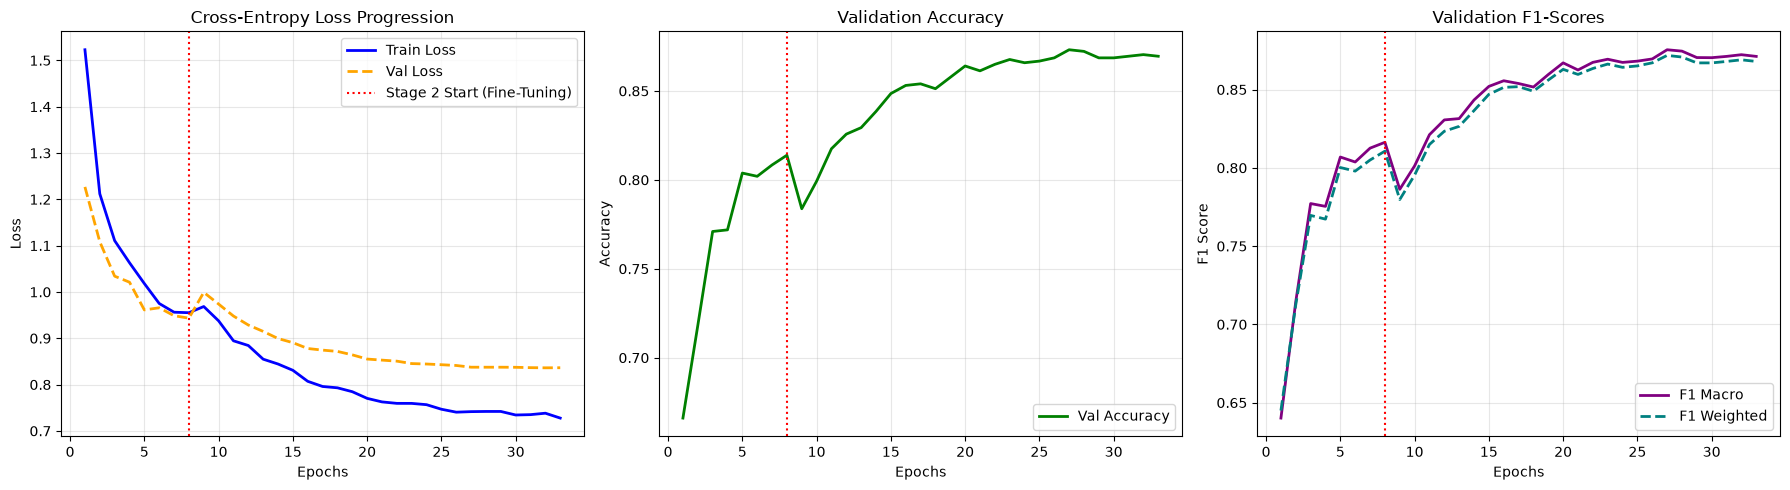

In [16]:
def plot_metrics(h1, h2):
    """Plots training and evaluation metrics across Stage 1 and Stage 2."""
    epochs_s1 = len(h1["train_loss"])
    epochs_s2 = len(h2["train_loss"])
    total_epochs = range(1, epochs_s1 + epochs_s2 + 1)

    train_loss = h1["train_loss"] + h2["train_loss"]
    val_loss = h1["val_loss"] + h2["val_loss"]
    val_acc = h1["val_acc"] + h2["val_acc"]
    val_f1_m = h1["val_f1_macro"] + h2["val_f1_macro"]
    val_f1_w = h1["val_f1_weighted"] + h2["val_f1_weighted"]

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    # Loss Plot
    axes[0].plot(
        total_epochs, train_loss, label="Train Loss", color="blue", linewidth=2
    )
    axes[0].plot(
        total_epochs,
        val_loss,
        label="Val Loss",
        color="orange",
        linestyle="--",
        linewidth=2,
    )
    axes[0].axvline(
        x=epochs_s1,
        color="red",
        linestyle=":",
        label="Stage 2 Start (Fine-Tuning)",
    )
    axes[0].set_title("Cross-Entropy Loss Progression")
    axes[0].set_xlabel("Epochs")
    axes[0].set_ylabel("Loss")
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    # Accuracy Plot
    axes[1].plot(total_epochs, val_acc, label="Val Accuracy", color="green", linewidth=2)
    axes[1].axvline(x=epochs_s1, color="red", linestyle=":")
    axes[1].set_title("Validation Accuracy")
    axes[1].set_xlabel("Epochs")
    axes[1].set_ylabel("Accuracy")
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    # F1 Scores Plot
    axes[2].plot(
        total_epochs, val_f1_m, label="F1 Macro", color="purple", linewidth=2
    )
    axes[2].plot(
        total_epochs,
        val_f1_w,
        label="F1 Weighted",
        color="teal",
        linestyle="--",
        linewidth=2,
    )
    axes[2].axvline(x=epochs_s1, color="red", linestyle=":")
    axes[2].set_title("Validation F1-Scores")
    axes[2].set_xlabel("Epochs")
    axes[2].set_ylabel("F1 Score")
    axes[2].legend()
    axes[2].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig("training_metrics.png", dpi=300)
    plt.show()

# ---------------------- Plot Results ---------------------- #
plot_metrics(history_stage1, history_stage2)

## Test Model
### Basic Tests

In [5]:
from sklearn.metrics import classification_report

def test_model(model, test_loader, criterion, model_path, class_names):
    """Evaluates best saved checkpoint on unseen testing data."""
    print("\n================ Testing Final Model ================")
    model.load_state_dict(torch.load(model_path))

    test_loss, test_acc, f1_macro, f1_weighted, preds, targets = evaluate(
        model, test_loader, criterion
    )

    print(
        f"Test Loss: {test_loss:.4f} | Test Accuracy: {test_acc:.4f} | "
        f"Test F1-Macro: {f1_macro:.4f} | Test F1-Weighted: {f1_weighted:.4f}\n"
    )

    print("Detailed Classification Report:")
    print(
        classification_report(
            targets, preds, target_names=class_names, digits=4
        )
    )

class_names = train_ds.classes
test_model(
    model, test_loader, criterion, stage2_path, class_names=class_names
)


================ Testing Final Model ================
Test Loss: 0.8780 | Test Accuracy: 0.8538 | Test F1-Macro: 0.8588 | Test F1-Weighted: 0.8532

Detailed Classification Report:
                     precision    recall  f1-score   support

          Cardboard     0.8816    0.8481    0.8645        79
      Food Organics     0.8824    0.8696    0.8759        69
              Glass     0.8551    0.8429    0.8489        70
              Metal     0.8298    0.8417    0.8357       139
Miscellaneous Trash     0.8806    0.7195    0.7919        82
              Paper     0.8556    0.8750    0.8652        88
            Plastic     0.7988    0.8562    0.8265       153
      Textile Trash     0.8519    0.8679    0.8598        53
         Vegetation     0.9359    0.9865    0.9605        74

           accuracy                         0.8538       807
          macro avg     0.8635    0.8564    0.8588       807
       weighted avg     0.8548    0.8538    0.8532       807



### Confusion Matrix

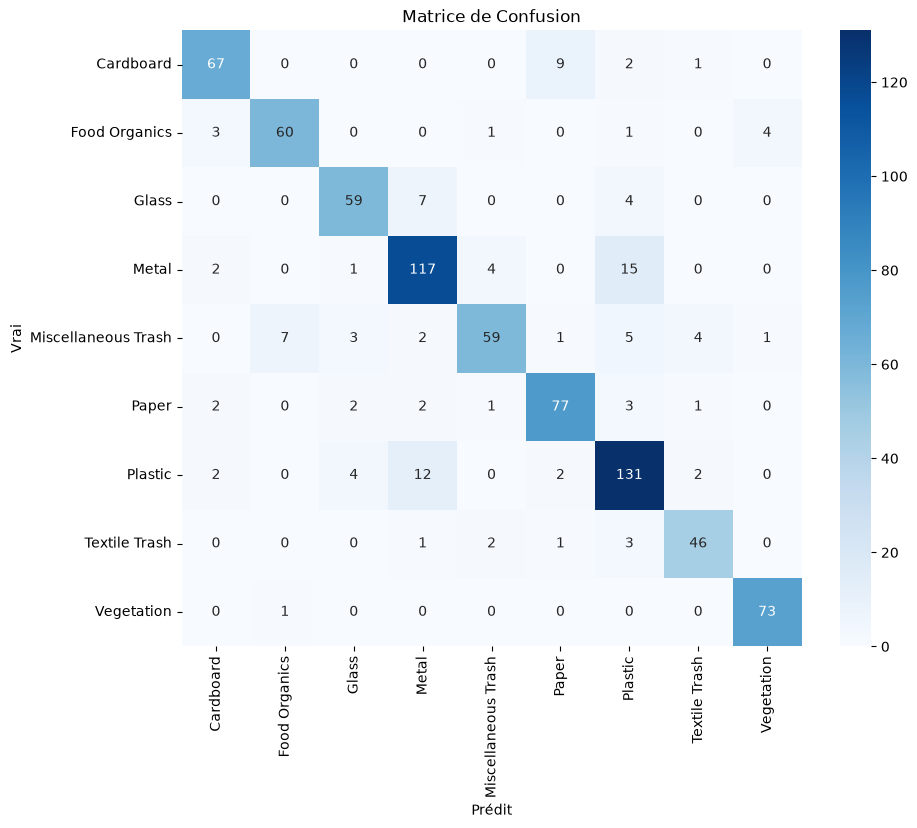

In [15]:
import seaborn as sns
from sklearn.metrics import confusion_matrix


def plot_confusion_matrix(all_labels, all_preds, class_names):
    cm = confusion_matrix(all_labels, all_preds)
    plt.figure(figsize=(10, 8))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names,
    )
    plt.xlabel("Prédit")
    plt.ylabel("Vrai")
    plt.title("Matrice de Confusion")
    plt.savefig("matrice_confusion.png")
    plt.show()

model.load_state_dict(torch.load(output_dir / f"mobilenet_v3_{dataset_name}_stage2.pt"))

test_loss, test_acc, f1_macro, f1_weighted, preds, targets = evaluate(
    model, test_loader, criterion
)

class_names = test_ds.classes

plot_confusion_matrix(targets, preds, class_names)

### Score Function

In [7]:
def score(model, X, y):
    with torch.no_grad():
        outputs = model(X)
        probs = nn.functional.softmax(outputs, dim=1).numpy()
    scores = []
    for (i, p) in enumerate(probs):
        order = np.argsort(p)[::-1]
        true_pos = np.where(order.copy() == y[i])[0][0]
        scores.append(p[order[:true_pos]].sum())
    return scores

def calibration(model, cal_loader, alpha):
    all_scores = []
    for images, labels in cal_loader:
        all_scores += score(model, images, labels)
    all_scores = np.array(all_scores)
    n = len(all_scores)
    q_hat = np.quantile(all_scores, np.ceil((n + 1) * (1 - alpha)) / n)
    return q_hat

In [8]:
# def score(model, X, y):
#     with torch.no_grad():
#         outputs = model(X)
#         probs = nn.functional.softmax(outputs, dim=1).numpy()
#     y_idx = y.numpy()
#     true_class_probs = probs[np.arange(len(probs)), y_idx]
#     return 1 - true_class_probs

# def calibration(model, cal_loader, alpha):
#     all_scores = []
#     for images, labels in cal_loader:
#         all_scores.extend(score(model, images, labels))
#     all_scores = np.array(all_scores)
#     n = len(all_scores)
#     q_hat = np.quantile(all_scores, np.ceil((n + 1) * (1 - alpha)) / n, method='higher')
#     return q_hat

In [9]:
alpha = 0.05
model_path = stage2_path
model.load_state_dict(torch.load(model_path))
model.eval()

q_hat = calibration(model, cal_loader, alpha)

total_predicted = 0
coverage_correct = 0
total_set_size = 0

n_labels = 9

with torch.no_grad():
    for images, labels in test_loader:
        outputs = model(images)
        probs_batch = nn.functional.softmax(outputs, dim=1).numpy()
        for i in range(len(images)):
            probs = probs_batch[i]
            
            pred_set = []
            order = np.argsort(probs)[::-1]
            cum = 0.0
            
            for idx in order:
                if cum > q_hat:
                    break
                pred_set.append(idx)
                cum += probs[idx]
        
            # for j in range(n_labels):
            #     prob_cls = probs[j]
            #     score_cls = 1.0 - prob_cls
        
            #     if score_cls <= q_hat:
            #         pred_set.append(j)
                
            true_label = labels[i]
        
            total_predicted += 1
            total_set_size += len(pred_set)
            if true_label in pred_set:
                coverage_correct += 1

print(f"Final Coverage: {100.0 * coverage_correct / total_predicted:.2f}%")
print(f"Final Average Set Size: {total_set_size / total_predicted:.2f}")
print(f"Quantile q_hat: {q_hat:.4f}")

Final Coverage: 94.55%
Final Average Set Size: 1.49
Quantile q_hat: 0.6880


In [14]:
import numpy as np
import torch
import torch.nn as nn
from collections import defaultdict

def evaluate_per_class_coverage(model, test_loader, q_hat, n_labels, device="cpu"):
    """
    Calculates empirical coverage and average prediction set size per class.
    
    Args:
        model: PyTorch model evaluated in eval mode.
        test_loader: DataLoader containing test dataset.
        q_hat (float): Quantile threshold obtained during calibration.
        n_labels (int): Total number of unique target classes.
        device (str or torch.device): Device to run tensor operations.
        
    Returns:
        dict: Summary containing overall statistics and per-class metrics.
    """
    model.eval()
    
    # Store metrics per class
    class_total = defaultdict(int)
    class_coverage = defaultdict(int)
    class_set_size = defaultdict(list)
    
    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            outputs = model(images)
            probs_batch = nn.functional.softmax(outputs, dim=1).cpu().numpy()
            labels_np = labels.cpu().numpy()
            
            for i in range(len(images)):
                probs = probs_batch[i]
                true_label = labels_np[i]
                
                # Construct prediction set using adaptive cumulative probability cutoff (APS)
                order = np.argsort(probs)[::-1]
                pred_set = []
                cum = 0.0
                
                for idx in order:
                    if cum > q_hat:
                        break
                    pred_set.append(idx)
                    cum += probs[idx]
                
                class_total[true_label] += 1
                class_set_size[true_label].append(len(pred_set))
                if true_label in pred_set:
                    class_coverage[true_label] += 1

    results = {}
    print(f"{'Class':<20} | {'Coverage (%)':<15} | {'Avg Set Size':<15} | {'Samples':<8}")
    print("-" * 68)
    
    for cls in range(n_labels):
        total = class_total[cls]
        if total > 0:
            cov = 100.0 * class_coverage[cls] / total
            avg_size = np.mean(class_set_size[cls])
            results[cls] = {
                "coverage": cov,
                "avg_set_size": avg_size,
                "count": total
            }
            print(f"{class_labels[cls]:<20} | {cov:<15.2f} | {avg_size:<15.2f} | {total:<8}")
        else:
            results[cls] = {"coverage": 0.0, "avg_set_size": 0.0, "count": 0}
            print(f"{cls:<8} | {'N/A':<15} | {'N/A':<15} | {0:<8}")
            
    return results

per_class_results = evaluate_per_class_coverage(
    model=model, 
    test_loader=test_loader, 
    q_hat=q_hat, 
    n_labels=9,
    device="cuda" if torch.cuda.is_available() else "cpu"
)

Class                | Coverage (%)    | Avg Set Size    | Samples 
--------------------------------------------------------------------
Cardboard            | 97.47           | 1.54            | 79      
Food Organics        | 95.65           | 1.38            | 69      
Glass                | 92.86           | 1.41            | 70      
Metal                | 93.53           | 1.49            | 139     
Paper                | 92.68           | 2.05            | 82      
Plastic              | 95.45           | 1.48            | 88      
Miscellaneous Trash  | 91.50           | 1.42            | 153     
Textile Trash        | 96.23           | 1.47            | 53      
Vegetation           | 100.00          | 1.11            | 74      


Example 1


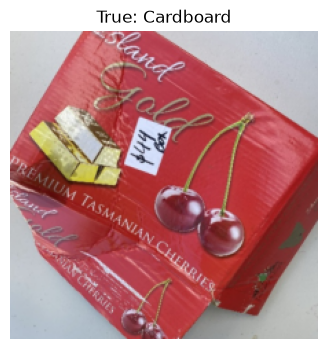

  True label:       Cardboard
  Prediction set:   ['Cardboard']
  Set size:          1
  Covered:           True
  Class probabilities and conformity scores:
    Cardboard: probability=0.8160, score=0.0000, 
    Plastic: probability=0.0796, score=0.8160, 
    Metal: probability=0.0301, score=0.8955, 
    Vegetation: probability=0.0266, score=0.9257, 
    Food Organics: probability=0.0206, score=0.9523, 
    Glass: probability=0.0161, score=0.9729, 
    Textile Trash: probability=0.0071, score=0.9890, 
    Paper: probability=0.0021, score=0.9961, 
    Miscellaneous Trash: probability=0.0018, score=0.9982, 

Example 1


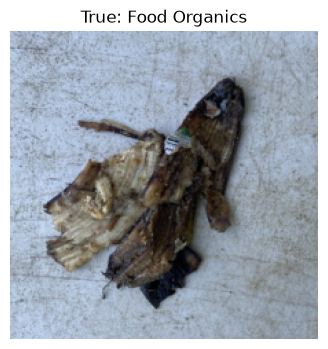

  True label:       Food Organics
  Prediction set:   ['Paper', 'Vegetation', 'Textile Trash']
  Set size:          3
  Covered:           False
  Class probabilities and conformity scores:
    Paper: probability=0.3729, score=0.0000, 
    Vegetation: probability=0.2046, score=0.3729, 
    Textile Trash: probability=0.1796, score=0.5775, 
    Food Organics: probability=0.1107, score=0.7572, 
    Plastic: probability=0.0573, score=0.8679, 
    Glass: probability=0.0372, score=0.9252, 
    Metal: probability=0.0136, score=0.9624, 
    Miscellaneous Trash: probability=0.0122, score=0.9760, 
    Cardboard: probability=0.0118, score=0.9882, 

Example 1


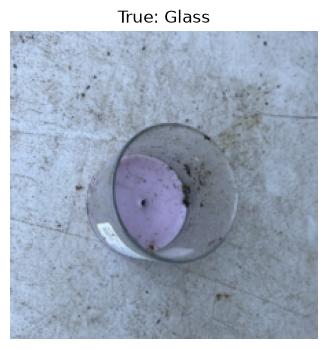

  True label:       Glass
  Prediction set:   ['Metal', 'Miscellaneous Trash', 'Glass']
  Set size:          3
  Covered:           True
  Class probabilities and conformity scores:
    Metal: probability=0.2707, score=0.0000, 
    Miscellaneous Trash: probability=0.2103, score=0.2707, 
    Glass: probability=0.2096, score=0.4811, 
    Paper: probability=0.1335, score=0.6907, 
    Food Organics: probability=0.0821, score=0.8242, 
    Vegetation: probability=0.0324, score=0.9062, 
    Textile Trash: probability=0.0284, score=0.9386, 
    Plastic: probability=0.0177, score=0.9671, 
    Cardboard: probability=0.0152, score=0.9848, 

Example 1


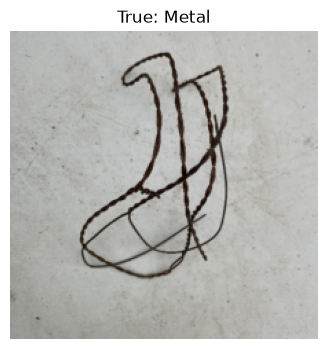

  True label:       Metal
  Prediction set:   ['Metal', 'Paper']
  Set size:          2
  Covered:           True
  Class probabilities and conformity scores:
    Metal: probability=0.6657, score=0.0000, 
    Paper: probability=0.1133, score=0.6657, 
    Vegetation: probability=0.0788, score=0.7790, 
    Miscellaneous Trash: probability=0.0496, score=0.8578, 
    Textile Trash: probability=0.0406, score=0.9074, 
    Plastic: probability=0.0190, score=0.9480, 
    Glass: probability=0.0128, score=0.9670, 
    Cardboard: probability=0.0119, score=0.9798, 
    Food Organics: probability=0.0082, score=0.9918, 

Example 1


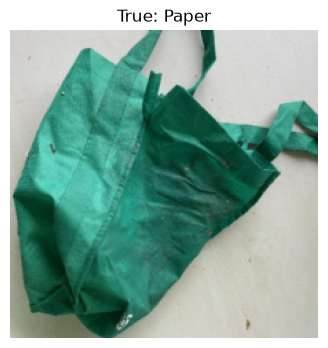

  True label:       Paper
  Prediction set:   ['Paper']
  Set size:          1
  Covered:           True
  Class probabilities and conformity scores:
    Paper: probability=0.8122, score=0.0000, 
    Textile Trash: probability=0.1443, score=0.8122, 
    Plastic: probability=0.0146, score=0.9565, 
    Miscellaneous Trash: probability=0.0106, score=0.9711, 
    Vegetation: probability=0.0073, score=0.9817, 
    Food Organics: probability=0.0046, score=0.9890, 
    Metal: probability=0.0034, score=0.9937, 
    Cardboard: probability=0.0024, score=0.9970, 
    Glass: probability=0.0006, score=0.9994, 

Example 1


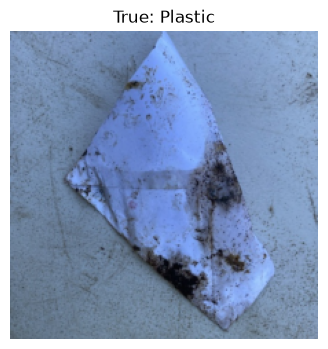

  True label:       Plastic
  Prediction set:   ['Plastic', 'Miscellaneous Trash']
  Set size:          2
  Covered:           True
  Class probabilities and conformity scores:
    Plastic: probability=0.3692, score=0.0000, 
    Miscellaneous Trash: probability=0.3204, score=0.3692, 
    Food Organics: probability=0.0964, score=0.6895, 
    Cardboard: probability=0.0692, score=0.7859, 
    Paper: probability=0.0669, score=0.8551, 
    Glass: probability=0.0267, score=0.9221, 
    Metal: probability=0.0202, score=0.9488, 
    Vegetation: probability=0.0164, score=0.9689, 
    Textile Trash: probability=0.0146, score=0.9854, 

Example 1


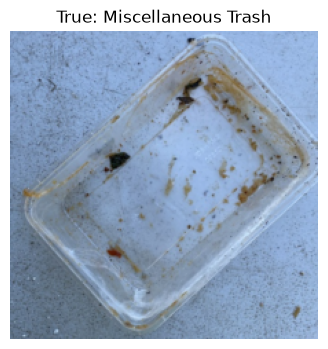

  True label:       Miscellaneous Trash
  Prediction set:   ['Miscellaneous Trash']
  Set size:          1
  Covered:           True
  Class probabilities and conformity scores:
    Miscellaneous Trash: probability=0.9941, score=0.0000, 
    Cardboard: probability=0.0020, score=0.9941, 
    Paper: probability=0.0013, score=0.9961, 
    Glass: probability=0.0010, score=0.9974, 
    Food Organics: probability=0.0008, score=0.9984, 
    Vegetation: probability=0.0003, score=0.9992, 
    Metal: probability=0.0002, score=0.9996, 
    Textile Trash: probability=0.0001, score=0.9998, 
    Plastic: probability=0.0001, score=0.9999, 

Example 1


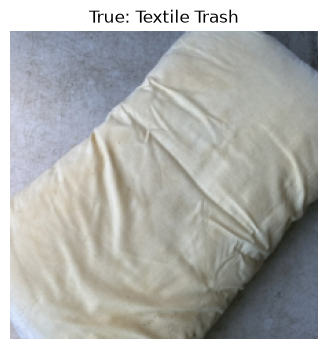

  True label:       Textile Trash
  Prediction set:   ['Miscellaneous Trash', 'Textile Trash', 'Paper', 'Cardboard']
  Set size:          4
  Covered:           True
  Class probabilities and conformity scores:
    Miscellaneous Trash: probability=0.2709, score=0.0000, 
    Textile Trash: probability=0.2660, score=0.2709, 
    Paper: probability=0.1400, score=0.5369, 
    Cardboard: probability=0.1073, score=0.6769, 
    Plastic: probability=0.0854, score=0.7842, 
    Vegetation: probability=0.0386, score=0.8696, 
    Metal: probability=0.0379, score=0.9082, 
    Glass: probability=0.0312, score=0.9461, 
    Food Organics: probability=0.0227, score=0.9773, 

Example 1


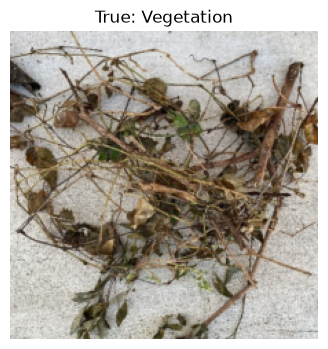

  True label:       Vegetation
  Prediction set:   ['Vegetation']
  Set size:          1
  Covered:           True
  Class probabilities and conformity scores:
    Vegetation: probability=0.9615, score=0.0000, 
    Paper: probability=0.0096, score=0.9615, 
    Glass: probability=0.0057, score=0.9712, 
    Food Organics: probability=0.0057, score=0.9769, 
    Cardboard: probability=0.0050, score=0.9826, 
    Metal: probability=0.0045, score=0.9876, 
    Miscellaneous Trash: probability=0.0038, score=0.9921, 
    Textile Trash: probability=0.0022, score=0.9959, 
    Plastic: probability=0.0020, score=0.9980, 



In [25]:
from collections import defaultdict
import random

def denormalize(tensor, mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]):
    """Reverses ImageNet normalization for displaying with matplotlib."""
    image = tensor.clone().permute(1, 2, 0).numpy()
    image = np.array(std) * image + np.array(mean)
    return np.clip(image, 0, 1)

def print_example_prediction_sets(
    model,
    dataset,
    q_hat,
    examples_per_class=1
):
    model.eval()

    targets = dataset.targets
    class_to_indices = defaultdict(list)
    for idx, target in enumerate(targets):
        class_to_indices[target].append(idx)
        
    for class_idx in sorted(class_to_indices.keys()):
        class_name = class_labels[class_idx]
        available_indices = class_to_indices[class_idx]

        selected_indices = random.sample(
            available_indices, 
            min(examples_per_class, len(available_indices))
        )

        for example_num, idx in enumerate(selected_indices, 1):
            x_img, y_true = dataset[idx]
            x_tensor = x_img.unsqueeze(0).to(device)
        
            with torch.no_grad():
                outputs = model(x_tensor)
                probs = nn.functional.softmax(outputs, dim=1).squeeze(0).numpy()
        
            prediction_set = []
            class_details = []

            
            order = np.argsort(probs)[::-1]
            cum = 0.0
            
            for idx in order:
                prob_cls = probs[idx]
                cls = class_labels[idx]
                score_cls = cum
                
                included = cum <= q_hat
                if included:
                    prediction_set.append(cls)

                cum += prob_cls

                class_details.append({
                    "class": cls,
                    "probability": prob_cls,
                    "conformity_score": score_cls,
                    "included": included,
                })
        
                
        
            true_label = class_labels[y_true]
            
            print(f"Example {example_num}")
            
            plt.figure(figsize=(4, 4))
            plt.imshow(denormalize(x_img))
            plt.title(f"True: {true_label}")
            plt.axis("off")
            plt.show()
            
            print(f"  True label:       {true_label}")
            print(f"  Prediction set:   {prediction_set}")
            print(f"  Set size:          {len(prediction_set)}")
            print(f"  Covered:           {true_label in prediction_set}")
        
            print("  Class probabilities and conformity scores:")
            for item in class_details:
                print(
                    f"    {item['class']}: "
                    f"probability={item['probability']:.4f}, "
                    f"score={item['conformity_score']:.4f}, "
                )
            print()

X, y = next(iter(test_loader))

print_example_prediction_sets(
    model,
    test_ds,
    q_hat=q_hat,
    examples_per_class=1
)